# 02 — Exploração do LUDB (conjunto de teste)

Verificação do dataset gerado por `scripts/preprocess_ludb.py`, com foco nas
regiões clínicas delimitadas pelos especialistas (ondas P, T e complexo QRS) —
o *ground truth* espacial contra o qual os mapas do Grad-CAM serão medidos.

Execute antes, na raiz do repositório:

```bash
python scripts/preprocess_ludb.py --download
```

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from xai_arrhythmia import config, io

dados = io.load_beat_dataset(config.LUDB_PROCESSED_FILE)

X = dados["series"]
y = dados["labels"]
simbolos = dados["simbolos"]
pacientes = dados["pacientes"]
tem_onda_p = dados["tem_onda_p"].astype(bool)

print(f"series    : {X.shape} {X.dtype}")
print(f"labels    : {np.bincount(y)} (0 = não-arritmia, 1 = arritmia)")
print(f"pacientes : {len(np.unique(pacientes))} registros")

series    : (1228, 234) float32
labels    : [1066  162] (0 = não-arritmia, 1 = arritmia)
pacientes : 179 registros


## 1. Distribuição por ritmo

O LUDB diagnostica o **registro**, não o batimento: o campo `Rhythm:` do header é
propagado para todos os batimentos daquele paciente.

In [3]:
ritmos, contagens = np.unique(simbolos, return_counts=True)
ordem = np.argsort(-contagens)

print(f"{'ritmo':<28} {'classe':>6} {'batimentos':>11} {'pacientes':>10} {'com P':>7}")
for i in ordem:
    ritmo = ritmos[i]
    seletor = simbolos == ritmo
    classe = int(y[seletor][0])
    n_pacientes = len(np.unique(pacientes[seletor]))
    frac_p = tem_onda_p[seletor].mean()
    print(
        f"{ritmo:<28} {classe:>6} {int(contagens[i]):>11} "
        f"{n_pacientes:>10} {frac_p:>6.0%}"
    )

ritmo                        classe  batimentos  pacientes   com P
sinus rhythm                      0         865        132   100%
atrial fibrillation               1         126         13     0%
sinus bradycardia                 0          75         17   100%
sinus arrhythmia                  0          64          8   100%
sinus tachycardia                 0          49          4   100%
atrial flutter, typical           1          36          3     0%
irregular sinus rhythm            0          13          2   100%


## 2. Função de plotagem

Sombreia as regiões anotadas usando as máscaras binárias. As máscaras incluem
**toda** onda delimitada que cai na janela — inclusive de batimentos vizinhos —
porque descrevem tudo que os especialistas marcaram naquele trecho. As chaves
`regiao_*` guardam apenas as ondas do próprio batimento.

In [9]:
CORES = {"p": "#fb8c00", "qrs": "#e53935", "t": "#43a047"}
ROTULOS = {"p": "Onda P", "qrs": "Complexo QRS", "t": "Onda T"}


def plot_batimento(idx, ax=None, legenda=True, titulo=True):
    """Plota um batimento com as regiões clínicas sombreadas."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3.2))

    sinal = X[idx]
    eixo_x = np.arange(len(sinal))
    baixo, alto = sinal.min(), sinal.max()
    margem = 0.12 * (alto - baixo)

    for tipo in ("p", "qrs", "t"):
        mascara = dados[f"mascara_{tipo}"][idx].astype(bool)
        if not mascara.any():
            continue
        ax.fill_between(
            eixo_x, baixo - margem, alto + margem,
            where=mascara, step="mid",
            color=CORES[tipo], alpha=0.28, linewidth=0,
            label=ROTULOS[tipo], zorder=1,
        )

    ax.plot(eixo_x, sinal, color="black", linewidth=1.4, zorder=3)
    ax.set_ylim(baixo - margem, alto + margem)
    ax.set_xlim(0, len(sinal) - 1)

    if titulo:
        marca_p = "" if tem_onda_p[idx] else "  [sem onda P]"
        ax.set_title(
            f"idx {idx} | paciente {pacientes[idx]} | {simbolos[idx]} | "
            f"classe {y[idx]}{marca_p}",
            fontsize=10,
        )
    if legenda:
        ax.legend(fontsize=8, loc="upper right", framealpha=0.9)
    return ax


def descrever_batimento(idx):
    """Imprime os metadados de um batimento, incluindo as regiões próprias."""
    print(f"--- Batimento índice {idx} ---")
    print(f"  paciente (registro)  : {pacientes[idx]}")
    print(f"  símbolo (ritmo)      : {simbolos[idx]}")
    classe = int(y[idx])
    print(f"  classe binária       : {classe} "
          f"({'não-arritmia' if classe == 0 else 'arritmia'})")
    print(f"  pico R no sinal      : {dados['r_peaks'][idx]}")
    print(f"  tem onda P           : {bool(tem_onda_p[idx])}")
    for tipo in ("p", "qrs", "t"):
        onset, offset = dados[f"regiao_{tipo}"][idx]
        if onset < 0:
            print(f"  região {ROTULOS[tipo]:<13}: ausente neste ritmo")
        else:
            largura = offset - onset + 1
            print(f"  região {ROTULOS[tipo]:<13}: [{onset:>3}, {offset:>3}] "
                  f"({largura} amostras, {1000 * largura / config.TARGET_FS:.0f} ms)")
    cobertura = dados["mascara_clinica"][idx].mean()
    print(f"  cobertura P+QRS+T    : {cobertura:.1%}")
    print()

## 3. Exemplo normal vs. arrítmico

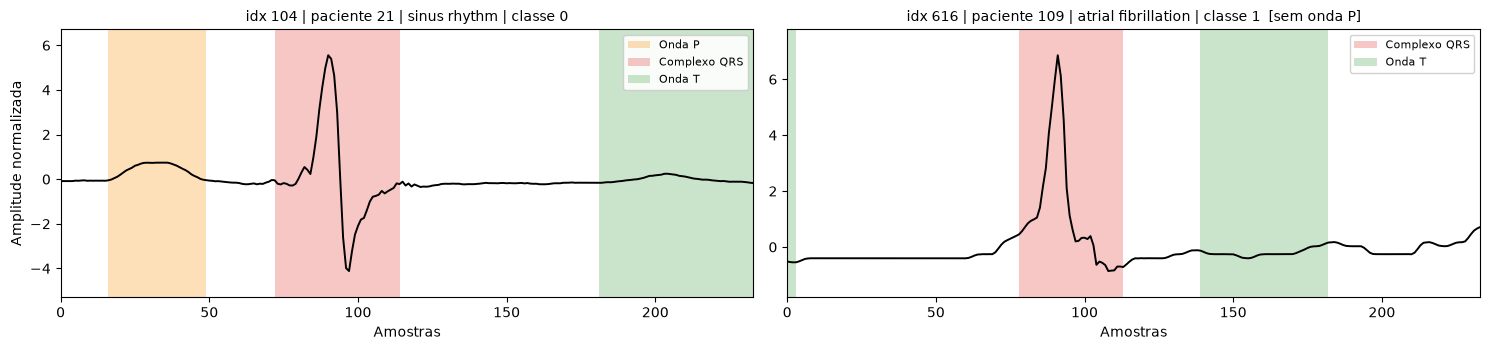

--- Batimento índice 104 ---
  paciente (registro)  : 21
  símbolo (ritmo)      : sinus rhythm
  classe binária       : 0 (não-arritmia)
  pico R no sinal      : 1891
  tem onda P           : True
  região Onda P       : [ 16,  49] (34 amostras, 94 ms)
  região Complexo QRS : [ 72, 114] (43 amostras, 119 ms)
  região Onda T       : [181, 233] (53 amostras, 147 ms)
  cobertura P+QRS+T    : 55.6%

--- Batimento índice 616 ---
  paciente (registro)  : 109
  símbolo (ritmo)      : atrial fibrillation
  classe binária       : 1 (arritmia)
  pico R no sinal      : 3297
  tem onda P           : False
  região Onda P       : ausente neste ritmo
  região Complexo QRS : [ 78, 113] (36 amostras, 100 ms)
  região Onda T       : [139, 182] (44 amostras, 122 ms)
  cobertura P+QRS+T    : 36.3%



In [10]:
rng = np.random.default_rng(42)

idx_normal = rng.choice(np.flatnonzero(y == 0))
idx_arritmico = rng.choice(np.flatnonzero(y == 1))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
plot_batimento(idx_normal, axes[0])
plot_batimento(idx_arritmico, axes[1])
axes[0].set_ylabel("Amplitude normalizada")
for ax in axes:
    ax.set_xlabel("Amostras")
fig.tight_layout()
plt.show()

descrever_batimento(idx_normal)
descrever_batimento(idx_arritmico)

## 4. Um exemplo de cada ritmo

Nos ritmos de fibrilação e flutter atrial a faixa laranja da onda P não aparece:
a onda P não existe nesses ritmos, e é por isso que o critério de inclusão a
exige apenas dos registros que a possuem.

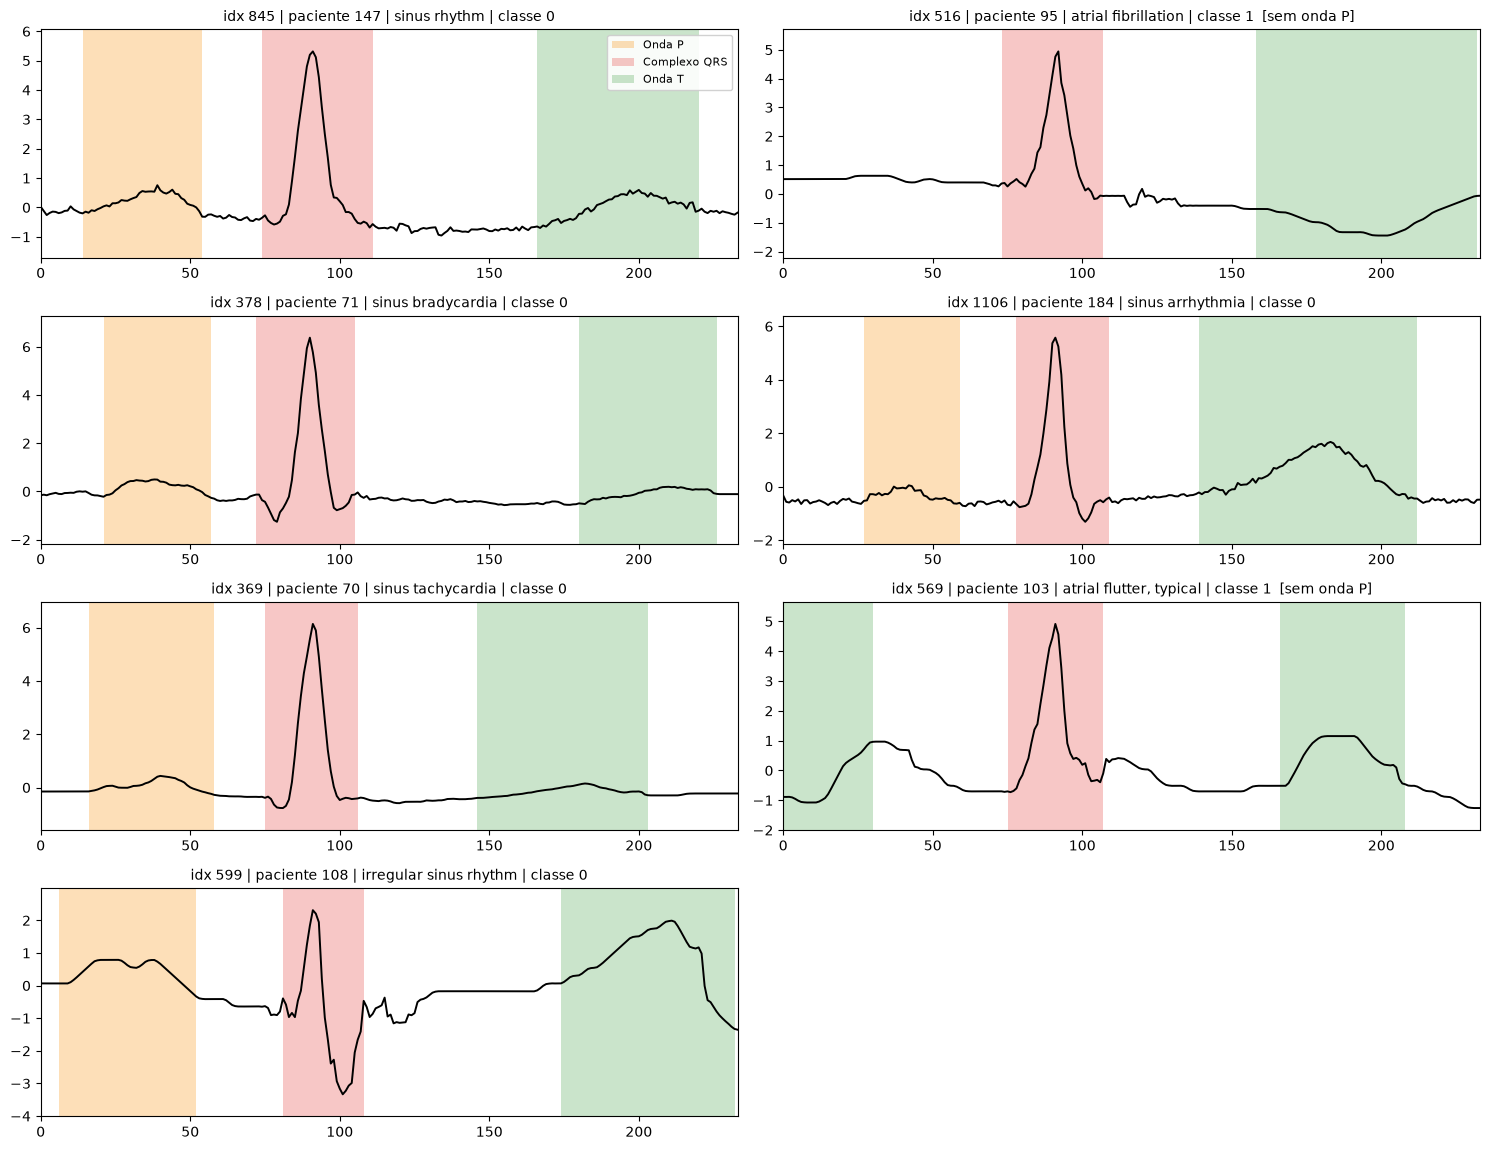

In [11]:
ritmos_ordenados = ritmos[ordem]
n_ritmos = len(ritmos_ordenados)
n_colunas = 2
n_linhas = int(np.ceil(n_ritmos / n_colunas))

fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(15, 2.9 * n_linhas))
axes = np.atleast_1d(axes).ravel()

for ax, ritmo in zip(axes, ritmos_ordenados):
    candidatos = np.flatnonzero(simbolos == ritmo)
    plot_batimento(rng.choice(candidatos), ax, legenda=False)

for ax in axes[n_ritmos:]:
    ax.axis("off")

axes[0].legend(fontsize=8, loc="upper right", framealpha=0.9)
fig.tight_layout()
plt.show()

## 5. Sobreposição de batimentos por classe

Confirma o alinhamento da segmentação: o pico R deve coincidir em todos os
batimentos, na amostra 90.

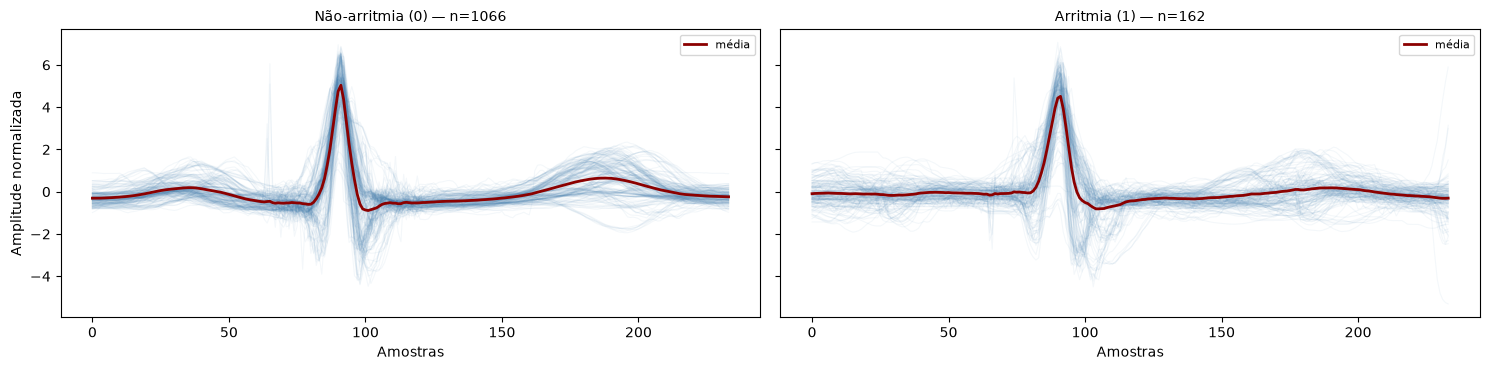

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)

for ax, classe, titulo in zip(axes, [0, 1], ["Não-arritmia (0)", "Arritmia (1)"]):
    amostras = X[y == classe][:200]
    ax.plot(amostras.T, color="steelblue", alpha=0.06, linewidth=0.8)
    ax.plot(amostras.mean(axis=0), color="darkred", linewidth=2, label="média")
    ax.set_title(f"{titulo} — n={int((y == classe).sum())}", fontsize=10)
    ax.set_xlabel("Amostras")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Amplitude normalizada")
fig.tight_layout()
plt.show()